# 18 · Data engineering for LLMs: deduplication, quality filtering, decontamination

"The data matters more than the model" is the most repeated sentence in LLM engineering, and it is mostly true: the open models that caught up with closed ones in 2023–2024 did it largely through better data, not new architectures (FineWeb, DCLM, Llama 3's data pipeline). This notebook builds the main steps of a web-scale pre-training data pipeline on a real sample, measures what each step removes and why, and then checks whether cleaning **actually changes the trained model**.

| step | question it answers | here |
|---|---|---|
| exact deduplication | is this document a byte-for-byte copy? | hashing normalized text |
| near-duplicate detection | is this document the same page with small edits? | **MinHash + LSH**, built from scratch and measured on planted duplicates |
| heuristic quality filters | is this text, or menus, spam and boilerplate? | the Gopher and C4 rules |
| model-based quality filter | is this text worth learning from? | the FineWeb-Edu classifier (a BERT encoder, notebook 17) |
| decontamination | does the training set contain the test set? | 13-gram overlap |
| synthetic data | can an LLM write training data? | `qwen2.5:3b`, and the diversity problem |
| does it matter? | does a model trained on clean data behave differently? | two `TransformerLM`s, same token budget |

Read it **before notebook 05**: this is what happens to text before a model ever sees it.

**Sources.** Huyen, *AI Engineering*, ch. 8 (dataset engineering); Stanford CS336, data lectures; Penedo et al. (2024), *The FineWeb Datasets*.

## Background: why data work is most of the work

### The pipeline

A modern pre-training corpus starts as raw web crawls (Common Crawl: billions of pages per snapshot) and is reduced by one to two orders of magnitude:

```
crawl (WARC) -> text extraction -> language ID -> URL / safety filters -> quality filters
             -> deduplication (exact, near-duplicate) -> decontamination -> mixing -> tokenization
```

FineWeb (Penedo et al., 2024) documents every step with ablations: each filter was kept only if a small model trained on the filtered data scored better on benchmarks. That is the method this notebook copies at small scale.

### Why duplicates hurt

Web crawls are highly redundant: mirrored sites, templates, syndicated articles, boilerplate. Lee et al. (2022, *Deduplicating Training Data Makes Language Models Better*) found single sequences repeated tens of thousands of times in C4. Duplicates:

- **waste compute**: the model pays again for text it has already seen;
- **cause memorization**: a sequence seen many times is reproduced verbatim (a privacy and copyright risk; Carlini et al., 2021, 2023);
- **leak evaluation**: a benchmark copied onto the web ends up in the training set and inflates scores.

### MinHash: estimating overlap without comparing every pair

Represent a document $A$ by its set of **shingles** (here, word 5-grams). The overlap of two documents is their **Jaccard similarity**

$$J(A, B) = \frac{|A \cap B|}{|A \cup B|}$$

Comparing all pairs is $O(N^2)$, which is impossible for billions of documents. **MinHash** (Broder, 1997) applies a random hash function $h$ to every shingle and keeps the minimum. For a random permutation,

$$\Pr\big[\min h(A) = \min h(B)\big] = J(A, B)$$

because the minimum over $A \cup B$ is equally likely to be any of its elements, and both minima coincide exactly when that element is in $A \cap B$. With $k$ independent hash functions, the share of matching minima in two **signatures** of length $k$ estimates $J$ with standard error $\sqrt{J(1-J)/k}$.

### LSH: finding the candidate pairs

**Locality-sensitive hashing** splits each signature into $b$ bands of $r$ rows and puts documents into buckets by each band. Two documents become candidates if *any* band matches exactly:

$$\Pr[\text{candidate}] = 1 - \big(1 - J^r\big)^b$$

This is an S-shaped curve with a soft threshold near $(1/b)^{1/r}$: pairs above it are almost always found, pairs below almost never. With $b = 16$ and $r = 8$ (128 hash functions) the threshold sits around $J \approx 0.71$. Production tools (`datatrove`, `text-dedup`, Spark implementations) do exactly this at the scale of billions of documents.

### Quality filtering

**Heuristic rules** remove what is obviously not prose. The Gopher rules (Rae et al., 2021) bound the number of words and the mean word length, and limit symbols, bullet lines and ellipses; they require common English stop words and penalize repeated lines and n-grams. The C4 rules (Raffel et al., 2020) keep lines that end in punctuation and drop pages with code-like braces or "lorem ipsum".

**Model-based filters** score each document with a small classifier trained to recognise good text. FineWeb-Edu trained a BERT regressor on 450,000 documents rated by Llama-3-70B for educational value (0–5); keeping documents scored 3 or more gave large gains on knowledge benchmarks at the same token budget. DCLM did the same with a fastText classifier. The trade-off: every filter also removes some good text, and a classifier encodes the taste of whoever labelled its data.

### Decontamination

If test questions are in the training data, benchmark scores measure memory, not ability. The standard check (GPT-3, Llama) indexes long n-grams (8 to 13 tokens) of every benchmark and flags training documents that share them. It is cheap and catches verbatim copies; paraphrased contamination needs embedding similarity or is simply not caught.

### Synthetic data

LLM-written text now makes up a large part of post-training data and a growing part of pre-training (the Phi models' "textbooks", Cosmopedia). It is controllable and cheap, but a model's samples are less diverse than human text, and training repeatedly on model outputs narrows the distribution (*model collapse*, Shumailov et al., 2024). Synthetic data needs the same deduplication and filtering as web data, plus explicit diversity measures.

**Key papers.** Broder (1997), *On the resemblance and containment of documents*; Rae et al. (2021), *Gopher*; Raffel et al. (2020), *T5 / C4*; Lee et al. (2022), *Deduplicating Training Data Makes Language Models Better*; Carlini et al. (2023), *Quantifying Memorization Across Neural Language Models*; Penedo et al. (2024), *The FineWeb Datasets*; Li et al. (2024), *DataComp-LM (DCLM)*; Shumailov et al. (2024), *AI models collapse when trained on recursively generated data*.

In [1]:
import os, sys, math, time, tempfile
ROOT = os.path.abspath(".")
while not os.path.isdir(os.path.join(ROOT, "llm_edu_suite")) and os.path.dirname(ROOT) != ROOT:
    ROOT = os.path.dirname(ROOT)                    # notebooks live in notebooks/<topic>/, so climb up to the repo root
sys.path.insert(0, ROOT)                            # so that `import llm_edu_suite` works from the notebook
import numpy as np
import matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as F
from llm_edu_suite.utils import seed_everything, get_device, count_params, human, show_mask
seed_everything(0)
device = get_device()
print("torch", torch.__version__, "| device", device)

torch 2.14.1+cu130 | device cuda


In [2]:
import json, re, random, hashlib, zlib, itertools, collections, logging, warnings
warnings.filterwarnings("ignore", message="IProgress not found")
logging.getLogger("torch.utils.flop_counter").setLevel(logging.ERROR)
import datasets, transformers, huggingface_hub
datasets.disable_progress_bars(); transformers.utils.logging.disable_progress_bar(); transformers.logging.set_verbosity_error()
huggingface_hub.utils.logging.set_verbosity_error(); huggingface_hub.utils.disable_progress_bars()

CACHE = os.path.join(ROOT, "data", "cache")
def stream_sample(name, config, n, path):
    """Stream the first n documents once and keep them on disk (data/cache/ is git-ignored; FineWeb is ODC-By, not redistributed here)."""
    path = os.path.join(CACHE, path)
    if not os.path.exists(path):
        os.makedirs(CACHE, exist_ok=True)
        ds = datasets.load_dataset(name, name=config, split="train", streaming=True)
        with open(path, "w", encoding="utf-8") as f:
            for d in itertools.islice(ds, n):
                f.write(json.dumps({"id": d["id"], "text": d["text"], "url": d.get("url", "")}) + "\n")
    return [json.loads(l) for l in open(path, encoding="utf-8")]

t0 = time.time()
web = stream_sample("HuggingFaceFW/fineweb", "sample-10BT", 12000, "fineweb_12k.jsonl")
edu = stream_sample("HuggingFaceFW/fineweb-edu", "sample-10BT", 1000, "fineweb_edu_1k.jsonl")
words = np.array([len(d["text"].split()) for d in web])
print(f"FineWeb sample: {len(web):,} documents, {words.sum() / 1e6:.1f}M words (median {int(np.median(words))} per document) | "
      f"FineWeb-Edu reference: {len(edu):,} documents | {time.time() - t0:.0f}s")

FineWeb sample: 12,000 documents, 6.2M words (median 297 per document) | FineWeb-Edu reference: 1,000 documents | 1s


## 1. A raw crawl, with known duplicates

FineWeb has already been deduplicated, so to measure deduplication we **simulate a raw crawl** with duplicates whose answer we know. From 10,000 base documents we add:

- 600 **exact copies** (a mirror site), and 50 documents copied **10 times each** (syndicated content, the case that drives memorization);
- 600 **near-duplicates** of four kinds: the same article on another site with another template (a new header and footer, text unchanged), and the same plus 1 %, 3 % or 10 % of the words replaced (light rewriting).

The last 2,000 FineWeb documents stay out of everything as a clean held-out set.

In [3]:
rng = random.Random(0)
base, heldout = web[:10000], web[10000:]
vocab_pool = [w for d in base[:500] for w in d["text"].split()][:200000]

def edit(text, rate, rng):
    """Replace `rate` of the words with random words, and wrap the page in a different site template."""
    w = text.split()
    for i in rng.sample(range(len(w)), int(rate * len(w))):
        w[i] = rng.choice(vocab_pool)
    return f"Home | News | Contact | Site {rng.randint(1, 999)}\n" + " ".join(w) + f"\nCopyright {rng.randint(1999, 2024)}. All rights reserved."

raw, origin = [], []                     # origin[i] = (index of the base document it copies, kind)
for i, d in enumerate(base):
    raw.append(d["text"]); origin.append((i, "original"))
long_docs = [i for i, d in enumerate(base) if 150 <= len(d["text"].split()) <= 1500]
picks = rng.sample(long_docs, 3050)
for i in picks[:600]:
    raw.append(base[i]["text"]); origin.append((i, "exact copy"))
REPEATED = picks[600:650]
for i in REPEATED:
    for _ in range(10):
        raw.append(base[i]["text"]); origin.append((i, "copied 10x"))
NEAR = {0.0: "template only", 0.01: "template + 1%", 0.03: "template + 3%", 0.10: "template + 10%"}
for k, (rate, kind) in enumerate(NEAR.items()):
    for i in picks[650 + 600 * k: 650 + 600 * (k + 1)]:
        raw.append(edit(base[i]["text"], rate, rng)); origin.append((i, kind))
kinds = collections.Counter(k for _, k in origin)
print(f"raw crawl: {len(raw):,} documents ->", dict(kinds))

raw crawl: 13,500 documents -> {'original': 10000, 'exact copy': 600, 'copied 10x': 500, 'template only': 600, 'template + 1%': 600, 'template + 3%': 600, 'template + 10%': 600}


## 2. Exact deduplication

Normalize (lowercase, collapse whitespace), hash with SHA-1 and keep the first document of each hash. It is linear in the corpus size and catches mirrors and syndicated copies, but a single changed character defeats it.

In [4]:
def norm(t):
    return " ".join(t.lower().split())
seen, keep_exact = set(), []
for i, t in enumerate(raw):
    h = hashlib.sha1(norm(t).encode()).hexdigest()
    if h not in seen:
        seen.add(h); keep_exact.append(i)
removed = collections.Counter(origin[i][1] for i in set(range(len(raw))) - set(keep_exact))
print(f"exact dedup: {len(raw):,} -> {len(keep_exact):,} documents | removed by kind: {dict(removed)}")

exact dedup: 13,500 -> 12,400 documents | removed by kind: {'exact copy': 600, 'copied 10x': 500}


## 3. Near-duplicate detection with MinHash + LSH, from scratch

Shingles are word 5-grams, hashed to 32 bits with CRC-32. Each of $k = 128$ hash functions is a random affine map $h_i(x) = (a_i x + b_i) \bmod p$ with a prime $p > 2^{32}$, and the signature keeps the minimum of each over the document's shingles. Then 16 bands of 8 rows, a dictionary of buckets per band, and every pair that shares a bucket is a candidate. A candidate is accepted if its signatures agree on at least 70 % of positions (the estimated Jaccard), and accepted pairs are merged into clusters with union-find. One document per cluster survives.

In [5]:
K, BANDS, ROWS, THRESH = 128, 16, 8, 0.7
P = (1 << 61) - 1
gen = np.random.default_rng(0)
A, B = gen.integers(1, P, K, dtype=np.uint64), gen.integers(0, P, K, dtype=np.uint64)

def shingles(text, n=5):
    w = re.findall(r"\w+", text.lower())
    return np.unique(np.array([zlib.crc32(" ".join(w[i:i + n]).encode()) for i in range(max(1, len(w) - n + 1))], dtype=np.uint64))

def signature(sh):
    # (K, n) affine hashes modulo a Mersenne prime, then the minimum per hash function
    return ((A[:, None] * sh[None, :] + B[:, None]) % np.uint64(P)).min(axis=1)

t0 = time.time()
docs = [raw[i] for i in keep_exact]
SH = [shingles(t) for t in docs]
SIG = np.stack([signature(s) for s in SH])
print(f"{len(docs):,} signatures of {K} hashes in {time.time() - t0:.0f}s")

buckets = collections.defaultdict(list)
for d, sig in enumerate(SIG):
    for b in range(BANDS):
        buckets[(b, sig[b * ROWS:(b + 1) * ROWS].tobytes())].append(d)
cands = {(x, y) for ids in buckets.values() if len(ids) > 1 for x, y in itertools.combinations(sorted(ids), 2)}
est = {pr: float((SIG[pr[0]] == SIG[pr[1]]).mean()) for pr in cands}
parent = list(range(len(docs)))
def find(x):
    while parent[x] != x:
        parent[x] = parent[parent[x]]; x = parent[x]
    return x
for (x, y), j in est.items():
    if j >= THRESH:
        parent[find(y)] = find(x)
keep_near = [keep_exact[d] for d in range(len(docs)) if find(d) == d]
print(f"{len(cands):,} candidate pairs from LSH, {sum(j >= THRESH for j in est.values()):,} accepted | "
      f"{len(keep_exact):,} -> {len(keep_near):,} documents | {time.time() - t0:.0f}s total")

12,400 signatures of 128 hashes in 12s


1,693 candidate pairs from LSH, 1,633 accepted | 12,400 -> 10,767 documents | 12s total


recall of planted near-duplicates:
  template only    100.0% of 600
  template + 1%    100.0% of 600
  template + 3%     72.2% of 600
  template + 10%     0.0% of 600
accepted pairs: 1,633, of which 0 join two different base documents (natural near-duplicates already in FineWeb, or false positives)


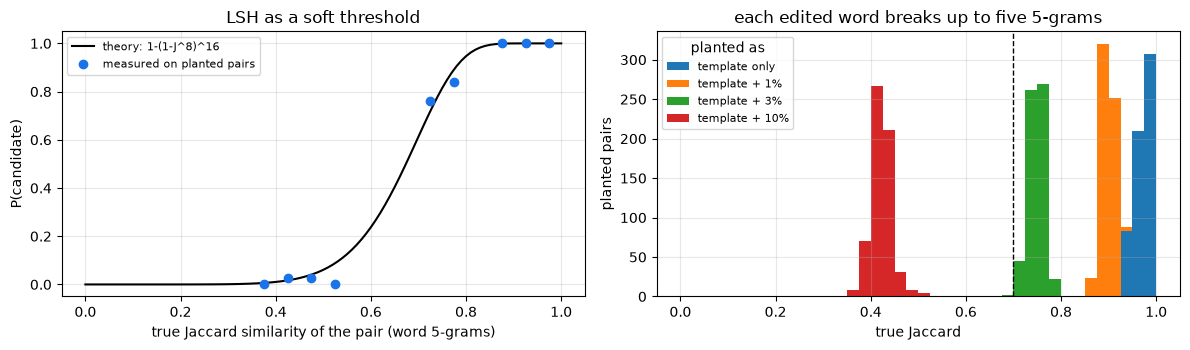

In [6]:
# Was each planted near-duplicate caught? It is caught if it ends up in the same cluster as the document it copies.
by_index = {i: d for d, i in enumerate(keep_exact)}
print("recall of planted near-duplicates:")
for kind in NEAR.values():
    pairs = [(i, o) for i, (o, k) in enumerate(origin) if k == kind and i in by_index and o in by_index]
    caught = np.mean([find(by_index[i]) == find(by_index[o]) for i, o in pairs])
    print(f"  {kind:16s} {caught:6.1%} of {len(pairs)}")
accepted = [pr for pr, j in est.items() if j >= THRESH]
cross = [pr for pr in accepted if origin[keep_exact[pr[0]]][0] != origin[keep_exact[pr[1]]][0]]
print(f"accepted pairs: {len(accepted):,}, of which {len(cross)} join two different base documents "
      f"(natural near-duplicates already in FineWeb, or false positives)")
for a, b in cross[:2]:
    print(f"  J~{est[(a, b)]:.2f}: {docs[a][:90]!r}\n          {docs[b][:90]!r}")

# true Jaccard of each planted pair vs whether LSH made it a candidate (the S-curve)
xs, ys, ks = [], [], []
for i, (o, kind) in enumerate(origin):
    if kind in NEAR.values() and i in by_index and o in by_index:
        a, b = SH[by_index[o]], SH[by_index[i]]
        xs.append(len(np.intersect1d(a, b)) / len(np.union1d(a, b)))
        ys.append(tuple(sorted((by_index[o], by_index[i]))) in cands); ks.append(kind)
xs, ys, ks = np.array(xs), np.array(ys), np.array(ks)
grid = np.linspace(0, 1, 101)
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
ax[0].plot(grid, 1 - (1 - grid ** ROWS) ** BANDS, color="black", label=f"theory: 1-(1-J^{ROWS})^{BANDS}")
bins = np.linspace(0, 1, 21); mid = (bins[:-1] + bins[1:]) / 2
rate = [ys[(xs >= lo) & (xs < hi)].mean() if ((xs >= lo) & (xs < hi)).sum() >= 5 else np.nan for lo, hi in zip(bins[:-1], bins[1:])]
ax[0].plot(mid, rate, "o", color="#1a73e8", label="measured on planted pairs")
ax[0].set_xlabel("true Jaccard similarity of the pair (word 5-grams)"); ax[0].set_ylabel("P(candidate)"); ax[0].legend(fontsize=8)
ax[0].set_title("LSH as a soft threshold"); ax[0].grid(alpha=.3)
ax[1].hist([xs[ks == k] for k in NEAR.values()], bins=np.linspace(0, 1, 41), stacked=True, label=list(NEAR.values()))
ax[1].axvline(THRESH, color="black", ls="--", lw=1); ax[1].set_xlabel("true Jaccard"); ax[1].set_ylabel("planted pairs"); ax[1].legend(title="planted as", fontsize=8)
ax[1].set_title("each edited word breaks up to five 5-grams"); ax[1].grid(alpha=.3)
plt.tight_layout(); plt.show()

**What the numbers say.** Exact hashing removed all 1,100 planted copies (13,500 → 12,400 documents) and nothing else. MinHash + LSH then found 1,693 candidate pairs, accepted 1,633 and removed another 1,633 documents (→ 10,767). The recall depends entirely on how much text two versions share:

- the same article in another template, and the same with 1 % of words rewritten: **100 %** caught;
- 3 % rewritten: 72.2 %;
- 10 % rewritten: 0 %.

The right panel explains why. One edited word breaks up to five word 5-grams, so 1 % of edits leaves a Jaccard around 0.9, 3 % leaves 0.72–0.78, right on the threshold, and 10 % drops it to about 0.42, where LSH by design does not look. The left panel is the best check that the implementation is right: the measured detection rates sit on the theoretical curve $1 - (1 - J^8)^{16}$. None of the 1,633 accepted pairs joined two different base documents, so at this threshold there were no false positives.

The design choice this exposes: the band and row counts set the threshold, and the threshold sets what "duplicate" means. FineWeb uses 5-grams and a threshold near 0.75, which removes templated copies and light rewrites but keeps documents that merely quote each other.

## 4. Quality filters: rules, then a classifier

We apply a compact version of the Gopher and C4 rules to the deduplicated corpus and record which rule removes each document, so the funnel is visible. Then the FineWeb-Edu classifier scores a sample of the survivors.

In [7]:
STOP = {"the", "be", "to", "of", "and", "that", "have", "with"}
def gopher_c4(text):
    """The first rule a document fails, or None. A compact version of Gopher (Rae et al., 2021) and C4 (Raffel et al., 2020)."""
    w = text.split()
    if not 50 <= len(w) <= 100_000: return "length (Gopher)"
    mean_len = sum(map(len, w)) / len(w)
    if not 3 <= mean_len <= 10: return "mean word length (Gopher)"
    if (text.count("#") + text.count("...")) / len(w) > 0.1: return "symbols (Gopher)"
    if sum(any(c.isalpha() for c in x) for x in w) / len(w) < 0.8: return "non-alphabetic words (Gopher)"
    if len(STOP & {x.lower() for x in w}) < 2: return "stop words (Gopher)"
    lines = [l.strip() for l in text.splitlines() if l.strip()]
    if lines and sum(l.startswith(("•", "-", "*", "·")) for l in lines) / len(lines) > 0.9: return "bullet lines (Gopher)"
    if lines and len(lines) - len(set(lines)) > 0.3 * len(lines): return "duplicate lines (Gopher)"
    if "lorem ipsum" in text.lower() or "{" in text: return "code or placeholder (C4)"
    if lines and sum(l.endswith((".", "!", "?", '"', "'")) for l in lines) / len(lines) < 0.3: return "few lines end in punctuation (C4)"
    return None

reasons = {i: gopher_c4(raw[i]) for i in keep_near}
keep_rules = [i for i in keep_near if reasons[i] is None]
funnel = collections.Counter(r for r in reasons.values() if r)
print(f"rule filters: {len(keep_near):,} -> {len(keep_rules):,} documents ({1 - len(keep_rules) / len(keep_near):.1%} removed)")
for r, n in funnel.most_common():
    print(f"  {r:38s} {n:5d}")
for r in list(funnel)[:3]:
    ex = next(i for i in keep_near if reasons[i] == r)
    print(f"\n[{r}] {raw[ex][:220]!r}")

rule filters: 10,767 -> 9,472 documents (12.0% removed)
  few lines end in punctuation (C4)       1173
  length (Gopher)                           66
  non-alphabetic words (Gopher)             29
  bullet lines (Gopher)                     14
  stop words (Gopher)                       11
  symbols (Gopher)                           1
  mean word length (Gopher)                  1

[few lines end in punctuation (C4)] '|Viewing Single Post From: Spoilers for the Week of February 11th|\n|Lil||Feb 1 2013, 09:58 AM|\nDon\'t care about Chloe/Taniel/Jen-Jen. Don\'t care about Sami, really, but hoping that we get some good "SAMANTHA GENE!!" Marl'

[non-alphabetic words (Gopher)] 'Larry Kim, Founder and Chief Technology Officer\nLarry Kim founded WordStream in 2007. He bootstrapped the company by providing internet consulting services while funding/managing a team of engineers and marketers to deve'

[length (Gopher)] 'Subject: Binary updates all installed pkgs? To: None <tech-pkg@NetBSD.org>

scored 4,500 documents in 35s
FineWeb after rules        mean score 1.20 | share >= 3 (FineWeb-Edu's threshold): 2.0%
rejected by the rules      mean score 1.00 | share >= 3 (FineWeb-Edu's threshold): 0.8%
FineWeb-Edu (reference)    mean score 3.04 | share >= 3 (FineWeb-Edu's threshold): 47.6%


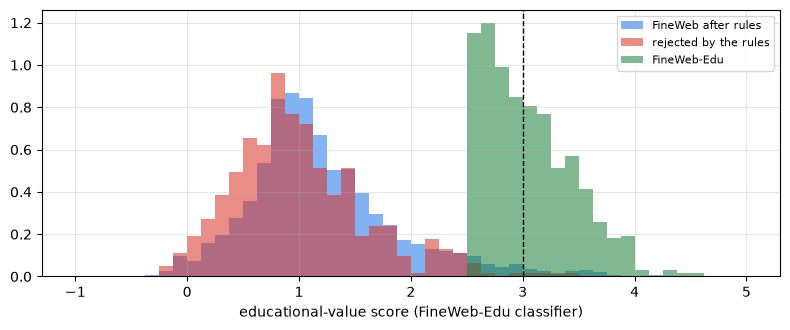


lowest-scored survivor: '| The site is owned and operated by ESS-COLOMBIA. Calle 65d, Medellín,Columbia | All rights reserved!\nINDEPENDENT ESCORTS BUCHAREST\nTERMS AND CONDITIONS FOR USE OF SITE\nBy clicking “AGREE AND ENTER” b'
highest-scored survivor: "Hawai'i Space Grant College, Hawai'i Institute of Geophysics and\nPlanetology, University of Hawai'i, 1996\nTo determine the factors affecting the appearance of impact craters\nThe circular features so o"


In [8]:
from transformers import AutoTokenizer, AutoModelForSequenceClassification
CLS_ID = "HuggingFaceFW/fineweb-edu-classifier"
qtok = AutoTokenizer.from_pretrained(CLS_ID)
qmodel = AutoModelForSequenceClassification.from_pretrained(CLS_ID).to(device).eval()

@torch.no_grad()
def edu_score(texts, bs=64):
    out = []
    for i in range(0, len(texts), bs):
        x = qtok(texts[i:i + bs], return_tensors="pt", padding=True, truncation=True, max_length=512).to(device)
        with torch.autocast(device, dtype=torch.bfloat16, enabled=device == "cuda"):
            out.append(qmodel(**x).logits.squeeze(-1).float().cpu().numpy())
    return np.concatenate(out)

t0 = time.time()
sample_ids = random.Random(1).sample(keep_rules, 3000)
s_web = edu_score([raw[i] for i in sample_ids])
s_edu = edu_score([d["text"] for d in edu])
s_rejected = edu_score([raw[i] for i in random.Random(2).sample([i for i in keep_near if reasons[i]], 500)])
print(f"scored {len(sample_ids) + len(edu) + 500:,} documents in {time.time() - t0:.0f}s")
for name, s in (("FineWeb after rules", s_web), ("rejected by the rules", s_rejected), ("FineWeb-Edu (reference)", s_edu)):
    print(f"{name:26s} mean score {s.mean():.2f} | share >= 3 (FineWeb-Edu's threshold): {(s >= 3).mean():.1%}")
fig, ax = plt.subplots(figsize=(8, 3.4))
for name, s, c in (("FineWeb after rules", s_web, "#1a73e8"), ("rejected by the rules", s_rejected, "#d93025"), ("FineWeb-Edu", s_edu, "#188038")):
    ax.hist(s, bins=np.linspace(-1, 5, 49), alpha=.55, density=True, color=c, label=name)
ax.axvline(3, color="black", ls="--", lw=1); ax.set_xlabel("educational-value score (FineWeb-Edu classifier)"); ax.legend(fontsize=8); ax.grid(alpha=.3)
plt.tight_layout(); plt.show()
order = np.argsort(s_web)
print("\nlowest-scored survivor:", repr(raw[sample_ids[order[0]]][:200]))
print("highest-scored survivor:", repr(raw[sample_ids[order[-1]]][:200]))

**What the numbers say.** The rules removed 12.0 % of the deduplicated documents (10,767 → 9,472). Almost all of it is the C4 rule on terminal punctuation (1,173 documents): forum threads, navigation menus and listings, where lines do not end in sentences. The Gopher rules caught a long tail of very short pages, symbol-heavy text and bullet lists.

The classifier shows how much further "quality" can go. On FineWeb after the rules, the mean educational score is 1.20 and only 2.0 % of documents reach 3, the FineWeb-Edu threshold; the reference FineWeb-Edu sample averages 3.04, with 47.6 % at 3 or more under our scoring (FineWeb-Edu rounds the score before thresholding, and we truncate at 512 tokens, so the figures are not identical to theirs). Rules and classifier also measure different things: documents the rules rejected score 1.00 on average, close to the ones they kept, and the lowest-scored *survivor* is the terms-and-conditions page of an escort site, well-formed prose that passes every rule. Heuristics remove what is not text; a classifier is needed to judge what the text is worth.

The cost is scale and bias: keeping only scores of 3 or more would throw away 98 % of this sample, and the classifier encodes one model's idea of "educational", which favours textbook prose over, for example, conversation or code.

## 5. Decontamination with 13-gram overlap

We treat 200 of the held-out documents as a "benchmark", paste the first 300 words of 50 of them into training documents (the way a test set leaks into a crawl), and look for training documents that share any word 13-gram with any benchmark document.

In [9]:
def ngrams(text, n=13):
    w = re.findall(r"\w+", text.lower())
    return {hash(" ".join(w[i:i + n])) for i in range(len(w) - n + 1)}
bench = heldout[:200]
bench_index = collections.defaultdict(set)
for b, d in enumerate(bench):
    for g in ngrams(d["text"]):
        bench_index[g].add(b)
train_docs = {i: raw[i] for i in keep_rules}
leak_rng = random.Random(3)
leaked = leak_rng.sample(range(200), 50)
targets = leak_rng.sample(list(train_docs), 50)
for b, i in zip(leaked, targets):
    train_docs[i] = train_docs[i] + "\n" + " ".join(bench[b]["text"].split()[:300])
t0 = time.time()
flagged = {i: set().union(*(bench_index[g] for g in ngrams(t) if g in bench_index)) for i, t in train_docs.items()}
flagged = {i: b for i, b in flagged.items() if b}
caught = sum(1 for b, i in zip(leaked, targets) if b in flagged.get(i, set()))
extra = [i for i in flagged if i not in targets]
print(f"scanned {len(train_docs):,} training documents in {time.time() - t0:.0f}s | leaked benchmark documents found: {caught} of 50 | "
      f"other training documents flagged: {len(extra)}")
for i in extra[:2]:
    print("  e.g.", repr(train_docs[i][:150]))

scanned 9,472 training documents in 6s | leaked benchmark documents found: 50 of 50 | other training documents flagged: 29
  e.g. 'MEXICO CITY (AP) - Authorities say 158 local police officers have been detained in northern Mexico for alleged ties to organized crime.\nDurango state '
  e.g. 'US reviews Mediterranean military presence\nRegional instability could drive increased attention\nSenior U.S. military officials are considering increas'


**What the numbers say.** All 50 planted benchmark passages were found (50 of 50) in 6 s. More interesting are the 29 *other* training documents flagged: none of them was planted. They share 13-grams with the benchmark documents because the web repeats itself, as the two examples above show (Associated Press stories republished by different news sites). This is how real contamination happens: nobody copies the test set on purpose, the same text simply exists in both places. A benchmark built from web text has to be checked against the training corpus, and every flagged document either removed or reported.

## 6. Does cleaning change the model?

The decisive test, as in FineWeb's ablations: train two identical `TransformerLM`s (notebook 05) on the same number of tokens, one on the **raw crawl** (all duplicates, no filters) and one on the **clean corpus** (deduplicated and rule-filtered), and compare them on

- the **held-out** FineWeb documents that neither saw: does cleaning help the model generalize?
- the **50 documents that were copied 10 times** into the raw crawl (present once in the clean corpus): does duplication cause memorization?

The tokenizer is SmolLM2's (a real 49k-token BPE), and the model has 4 layers of width 256.

In [10]:
from llm_edu_suite.model import ModelConfig, TransformerLM
tok = AutoTokenizer.from_pretrained("HuggingFaceTB/SmolLM2-135M")
EOS = tok.eos_token_id
def encode(texts):
    ids = []
    for t in texts:
        ids.extend(tok(t, add_special_tokens=False)["input_ids"]); ids.append(EOS)
    return torch.tensor(ids, dtype=torch.long)

clean_ids = [i for i in keep_rules]
t0 = time.time()
corpora = {"raw crawl": encode(raw), "clean (dedup + rules)": encode([raw[i] for i in clean_ids])}
held = encode([d["text"] for d in heldout[:1000]])
clean_set = set(clean_ids)   # only repeated documents that survive cleaning, so both models have seen them
memo = {i: tok(base[i]["text"], add_special_tokens=False, return_tensors="pt")["input_ids"][0][:256] for i in REPEATED if i in clean_set}
print({k: f"{len(v) / 1e6:.1f}M tokens" for k, v in corpora.items()}, f"| held-out {len(held) / 1e6:.2f}M tokens | "
      f"{len(memo)} of the 50 repeated documents survive cleaning | {time.time() - t0:.0f}s")

CTX, BS, STEPS = 256, 32, 1500
def train(stream, seed=0):
    seed_everything(seed)
    m = TransformerLM(ModelConfig(vocab_size=len(tok), max_seq_len=CTX, d_model=256, n_layers=4, n_heads=4, n_kv_heads=4)).to(device)
    opt = torch.optim.AdamW(m.parameters(), lr=1e-3, betas=(0.9, 0.95), weight_decay=0.1)
    sched = torch.optim.lr_scheduler.LambdaLR(opt, lambda s: min(1.0, (s + 1) / 100) * 0.5 * (1 + math.cos(math.pi * min(s, STEPS) / STEPS)))
    g = torch.Generator().manual_seed(seed)
    for step in range(STEPS):
        ix = torch.randint(0, len(stream) - CTX - 1, (BS,), generator=g)
        x = torch.stack([stream[i:i + CTX] for i in ix]).to(device); y = torch.stack([stream[i + 1:i + CTX + 1] for i in ix]).to(device)
        with torch.autocast(device, dtype=torch.bfloat16, enabled=device == "cuda"):
            _, loss = m(x, y)
        opt.zero_grad(set_to_none=True); loss.backward(); torch.nn.utils.clip_grad_norm_(m.parameters(), 1.0); opt.step(); sched.step()
    return m.eval()

@torch.no_grad()
def eval_loss(m, stream, n=400):
    g = torch.Generator().manual_seed(123); ix = torch.randint(0, len(stream) - CTX - 1, (n,), generator=g); losses = []
    for b in range(0, n, 50):
        x = torch.stack([stream[i:i + CTX] for i in ix[b:b + 50]]).to(device); y = torch.stack([stream[i + 1:i + CTX + 1] for i in ix[b:b + 50]]).to(device)
        losses.append(m(x, y)[1].item())
    return float(np.mean(losses))
@torch.no_grad()
def memo_loss(m):
    return float(np.mean([m(v[None, :-1].to(device), v[None, 1:].to(device))[1].item() for v in memo.values()]))

RESULT = {}
for name, stream in corpora.items():
    t0 = time.time(); m = train(stream)
    RESULT[name] = dict(held=eval_loss(m, held), memo=memo_loss(m), secs=time.time() - t0)
    print(f"{name:24s} held-out loss {RESULT[name]['held']:.3f} (perplexity {math.exp(RESULT[name]['held']):.0f}) | "
          f"loss on the 50 repeated documents {RESULT[name]['memo']:.3f} | {RESULT[name]['secs']:.0f}s")
    del m
    if device == "cuda": torch.cuda.empty_cache()

D:\Trabajo\proyectos\llm-egineering-suite\llm-engineering-suite\.venv\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\Andy\.cache\huggingface\hub\models--HuggingFaceTB--SmolLM2-135M. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


{'raw crawl': '9.5M tokens', 'clean (dedup + rules)': '6.9M tokens'} | held-out 0.77M tokens | 43 of the 50 repeated documents survive cleaning | 55s


raw crawl                held-out loss 5.547 (perplexity 257) | loss on the 50 repeated documents 4.350 | 686s


clean (dedup + rules)    held-out loss 5.537 (perplexity 254) | loss on the 50 repeated documents 5.281 | 612s


**What the numbers say.** Cleaning removed 27 % of the tokens (9.5M → 6.9M), and both models trained on the same 12.3M tokens (1,500 steps of 32 × 256), so the clean model simply saw its data more times.

- **Held-out text:** 5.547 (raw) against 5.537 (clean), perplexity 257 against 254. At this scale the difference is within noise. FineWeb measured the gains of filtering on models trained for billions of tokens and evaluated on benchmarks; a 16M-parameter model trained for a few minutes is far from that regime, and we report what we see.
- **Memorization:** on the 43 documents that were repeated ten times in the raw crawl (and survived cleaning, so the clean model saw each once), the raw model's loss is **4.350**, well below its loss on unseen text (5.547), while the clean model's is 5.281, close to its unseen-text loss. Ten copies were enough for a small model to start memorizing those pages, the effect Lee et al. (2022) and Carlini et al. (2023) measured on large models: duplication buys memorization, not knowledge.

So the robust, measurable benefit of deduplication even at small scale is less memorization at less cost (27 % fewer tokens to process here); the quality benefits need scale to show.

## 7. Synthetic data and its diversity problem

`qwen2.5:3b` writes short "textbook" passages on 20 topics, 3 samples each at temperature 0.8. We then treat them like any other data: how many are near-duplicates of each other (MinHash), how diverse is their vocabulary (distinct bigrams), and how does the quality classifier rate them?

In [11]:
from llm_edu_suite.config import get_llm
llm = get_llm(temperature=0.8, num_predict=220)
TOPICS = ["photosynthesis", "the French Revolution", "compound interest", "how vaccines work", "plate tectonics", "binary numbers",
          "the water cycle", "supply and demand", "Newton's laws of motion", "the human heart", "climate and weather", "prime numbers",
          "the Roman Empire", "DNA replication", "electric circuits", "the scientific method", "volcanoes", "probability",
          "the immune system", "renewable energy"]
prompts = [f"Write a short textbook paragraph (about 150 words) that explains {t} to a high-school student." for t in TOPICS for _ in range(3)]
t0 = time.time()
synth = [m.content for m in llm.batch(prompts, config={"max_concurrency": 4})]
print(f"{len(synth)} synthetic passages in {time.time() - t0:.0f}s | example:\n{synth[0][:300]}")

def distinct2(texts):
    bi = [tuple(w[i:i + 2]) for t in texts for w in [re.findall(r"\w+", t.lower())] for i in range(len(w) - 1)]
    return len(set(bi)) / max(1, len(bi))
def near_dup_rate(texts, thresh=0.5):
    sigs = [signature(shingles(t, n=3)) for t in texts]
    pairs = list(itertools.combinations(range(len(texts)), 2))
    sims = np.array([(sigs[a] == sigs[b]).mean() for a, b in pairs])
    same_topic = np.array([a // 3 == b // 3 for a, b in pairs])
    return sims[same_topic].mean(), sims[~same_topic].mean(), (sims[same_topic] >= thresh).mean()
real = [d["text"] for d in edu[:60]]
for name, texts in (("synthetic (qwen2.5:3b)", synth), ("FineWeb-Edu (human)", real)):
    sc = edu_score(texts)
    print(f"{name:24s} distinct bigrams {distinct2(texts):.2f} | educational score {sc.mean():.2f}, share >= 3: {(sc >= 3).mean():.0%}")
same, diff, dup = near_dup_rate(synth)
print(f"synthetic, estimated Jaccard of word 3-grams: same topic {same:.2f}, different topics {diff:.2f}; same-topic pairs above 0.5: {dup:.0%}")

60 synthetic passages in 196s | example:
Photosynthesis is a fundamental process that occurs in plants, algae, and some bacteria, allowing these organisms to convert light energy from the sun into chemical energy stored in glucose, a sugar that serves as the primary energy source for the organism. During photosynthesis, plants absorb carbo


synthetic (qwen2.5:3b)   distinct bigrams 0.60 | educational score 4.15, share >= 3: 100%


FineWeb-Edu (human)      distinct bigrams 0.72 | educational score 3.14, share >= 3: 57%
synthetic, estimated Jaccard of word 3-grams: same topic 0.09, different topics 0.00; same-topic pairs above 0.5: 0%


**What the numbers say.** Sixty passages took 196 s. The classifier rates them very highly, a mean educational score of **4.15** and 100 % at 3 or more, against 3.14 and 57 % for human FineWeb-Edu text. Their vocabulary is narrower: 0.60 distinct bigrams against 0.72. They are not near-duplicates of each other (same-topic pairs share only 0.09 of their 3-grams on average, none above 0.5), so the narrowing is subtler than copying: the same structure and phrasing patterns across topics.

Two lessons. A quality classifier trained on what "educational" text looks like rewards text written to look educational, so synthetic data can game the very filter meant to judge it, and it must be evaluated by downstream results, not by the classifier. And lexical diversity is the cheap early warning of the collapse that recursive training on model outputs causes; measure it on every synthetic set.

## Results

| step | measured | what it shows |
|---|---|---|
| exact dedup | 13,500 → 12,400 documents; all 1,100 planted copies removed, nothing else | cheap, exact, and blind to the smallest edit |
| MinHash + LSH (k = 128, 16 × 8, threshold 0.7) | recall 100 % (template, +1 %), 72.2 % (+3 %), 0 % (+10 %); 0 false merges; 12,400 → 10,767 | the measured detection rate follows the theoretical S-curve; the threshold defines "duplicate" |
| Gopher + C4 rules | 12.0 % removed, mostly lines without terminal punctuation (1,173) | rules remove menus, threads and fragments, not bad prose |
| FineWeb-Edu classifier | mean 1.20 and 2.0 % ≥ 3 on cleaned FineWeb vs 3.04 and 47.6 % on FineWeb-Edu | model-based filtering is far more selective; spam in good prose survives the rules |
| decontamination (13-grams) | 50 of 50 planted leaks found, plus 29 natural overlaps (syndicated news) | contamination happens on its own when the web repeats itself |
| training on raw vs clean (same 12.3M tokens) | held-out loss 5.547 vs 5.537 (noise); loss on 10×-repeated documents 4.350 vs 5.281 | at small scale, dedup's measurable effect is less memorization at 27 % fewer tokens |
| synthetic data (`qwen2.5:3b`) | classifier score 4.15 vs 3.14 human; distinct bigrams 0.60 vs 0.72 | synthetic text games quality classifiers and is less diverse |

## In production

**The pipeline.** Use a framework built for it rather than scripts: `datatrove` (Hugging Face, used for FineWeb) or NVIDIA NeMo Curator, both with MinHash dedup, Gopher/C4/FineWeb filters, language ID and PII redaction, running on many machines. Keep every step's decisions as data (a per-document reason, as in section 4), so filters can be audited and changed.

**Defaults that work.**
- Exact dedup on normalized text, then MinHash on word 5-grams with a threshold around 0.75. For hundreds of millions of documents, run dedup within each crawl snapshot first.
- Gopher and C4 rules as a baseline, then a model-based quality score on top. Choose the threshold with small training ablations, never by eye.
- Decontaminate against every benchmark you report, with 8 to 13-gram overlap, and publish what was removed.
- For synthetic data: varied prompts, personas and seeds; dedup and filter like web data; track lexical and embedding diversity; and evaluate by training on it.

**What to monitor.** The share of each source and filter over time, since a site change can flood the corpus with boilerplate. Duplicate rates per source. The score distribution of the quality classifier. A random sample read by a person at every release.

**Failure modes.**
- A threshold that silently removes a whole domain: code, other languages, or dialects that a classifier finds "low quality".
- Over-aggressive dedup that removes legitimate repetition, such as licences that must be present or common phrases.
- Benchmark contamination discovered after publication.
- Synthetic data that inflates the very metrics used to judge it.

**Next:** `05_pretraining.ipynb`, where text like this becomes a trained model.